Advent 2026 Assignment

Programme: Bachelor of Science in Data Science and Analytics  
Year: 2
Semester: 1  
Course: Data Mining and Wrangling  



GROUP MEMVBERS

1. AJAK DENG GARANG DENG                           M25B38/031
2. APONI ALLAN DANIEL                              M25B38/029
3. EZEKIEL BULIMA                                  M25B38/028

## Introduction

The work follows the assignment in order: understand the dataset, clean the data, summarize and visualize it, study relationships, explain the findings and limitations. However, the results show some patterns in this dataset.

# Source and description of the dataset

## Dataset source

The dataset used here is the Post-Pandemic Remote Work Health Impact 2025 dataset.

Public source: Kaggle - Remote Work Health Impact Survey 2025  

Working link: https://www.kaggle.com/datasets/pratyushpuri/remote-work-health-impact-survey-2025

The supplied description says that the data were collected in June 2025 and are intended to help study remote, hybrid and onsite work and employee well-being.

## Why we chose this dataset

We chose this dataset because remote and hybrid work are parts of modern working life mostly to us, Data Scientists. 

The dataset can help us answer questions such as:

- Which work arrangement has the most high burnout?
- How many hours do respondents work?
- Does age have a relationship with working hours?
- Does mental-health status vary between work arrangements?
- Are there differences between regions and industries?

Our interest for this dataset is that, we wanted to understand whether different work arrangements appear to have different burnout and mental-health patterns.

## Size and structure

The supplied CSV contains 3,157 rows and 10 original columns. One row represents one survey response.

The file contains both numerical and categorical variables, so it is suitable for the assignment. There are 2 numerical variables and 8 date/categorical variables in the original dataset.


In [132]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy import stats


# Sample

In [131]:
df = pd.read_csv('post_pandemic_remote_work_health_impact_2025-selected-columns.csv')
df.sample(200).sort_index()

,Survey_Date,Age,Gender,Region,Industry,Job_Role,Work_Arrangement,Hours_Per_Week,Mental_Health_Status,Burnout_Level
10,1/06/2025,42,Female,Asia,Professional Services,Project Manager,Onsite,38,NaN,High
45,1/06/2025,40,Male,North America,Professional Services,Customer Service Manager,Remote,62,Stress Disorder,Medium
50,1/06/2025,62,Female,Africa,Technology,DevOps Engineer,Remote,46,Depression,High
54,1/06/2025,44,Female,South America,Retail,Marketing Specialist,Onsite,48,NaN,Low
68,1/06/2025,22,Male,Oceania,Technology,Sales Representative,Onsite,43,Stress Disorder,Medium
...,...,...,...,...,...,...,...,...,...,...
3089,26/06/2025,53,Female,Europe,Professional Services,UX Designer,Hybrid,38,Depression,High
3095,26/06/2025,49,Female,Africa,Manufacturing,Customer Service Manager,Remote,38,NaN,Low
3107,26/06/2025,43,Prefer not to say,Africa,Education,Software Engineer,Onsite,60,NaN,Low
3128,26/06/2025,46,Male,Europe,Professional Services,Marketing Specialist,Onsite,57,NaN,Low


## The supplied CSV size

In [77]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 3157
Columns: 10


# Data type

In [78]:
## The assignment requires every variable to be described and accounted for

In [79]:
print("DATASET INFORMATION")
df.info()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3157 entries, 0 to 3156
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Survey_Date           3157 non-null   object
 1   Age                   3157 non-null   int64 
 2   Gender                3157 non-null   object
 3   Region                3157 non-null   object
 4   Industry              3157 non-null   object
 5   Job_Role              3157 non-null   object
 6   Work_Arrangement      3157 non-null   object
 7   Hours_Per_Week        3157 non-null   int64 
 8   Mental_Health_Status  2358 non-null   object
 9   Burnout_Level         3157 non-null   object
dtypes: int64(2), object(8)
memory usage: 246.8+ KB


## 2. Data cleaning

## What do we clean in a dataset?

Before analysis, we must make sure the data are suitable for use. Therefore, Iwe checked:

1. Missing values
2. Duplicate rows
3. Unnecessary spaces in text
4. Impossible numerical values(outliers)

For every problem, we explain what we found and why we handled it in a particular way.

## Missing values

In [80]:
missing_before = df.isna().sum()

In [81]:
print("Missing values:")
display(missing_before.to_frame("Missing_Values"))
print("Total missing cells:", int(missing_before.sum()))

Missing values:


,Missing_Values
Survey_Date,0
Age,0
Gender,0
Region,0
Industry,0
Job_Role,0
Work_Arrangement,0
Hours_Per_Week,0
Mental_Health_Status,799
Burnout_Level,0


Total missing cells: 799


The biggest problem is in `Mental_Health_Status`.
There are missing values in this column.

### What we decided

We will not delete these rows. Deleting them would remove useful information about those respondents, including age, work arrangement, industry and burnout.

Instead, we will replace the missing value with (Unknown / Not Reported).
This is better than guessing an answer for a respondent.

### Before cleaning

The graph below shows where the missing information is found.

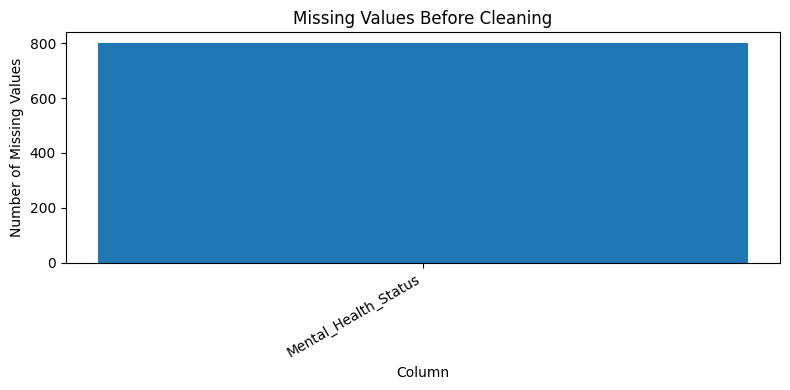

In [82]:
m = missing_before[missing_before > 0]
plt.figure(figsize=(8,4))
plt.bar(m.index, m.values)
plt.title("Missing Values Before Cleaning")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Interpretation:

 The missing information is concentrated in `Mental_Health_Status`. This confirms that this is the main missing-data issue in the dataset.

In [83]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


Therefore, there are no duplicate rows that need to be removed.

In [84]:
print("\\nChecking text values for leading spaces:")

for col in df.select_dtypes(include="object").columns:
    s = df[col].dropna().astype(str)
    print(col, "->", int((s != s.str.strip()).sum()), "values with extra spaces")

\nChecking text values for leading spaces:
Survey_Date -> 0 values with extra spaces
Gender -> 0 values with extra spaces
Region -> 0 values with extra spaces
Industry -> 0 values with extra spaces
Job_Role -> 0 values with extra spaces
Work_Arrangement -> 0 values with extra spaces
Mental_Health_Status -> 0 values with extra spaces
Burnout_Level -> 0 values with extra spaces


## Data types and text cleaning

`Survey_Date` is stored as text, but it represents a date. We will convert it to a proper date format.

We also checked the text columns for unnecessary spaces. Removing spaces at the beginning or end prevents categories such as `Remote` and ` Remote` from being treated as different groups.

## Age check

In [136]:
print("Minimum age:", df["Age"].min())
print("Maximum age:", df["Age"].max())
print("Invalid ages:", int(((df["Age"] < 18) | (df["Age"] > 100)).sum()))

Minimum age: 22
Maximum age: 65
Invalid ages: 0


## Hours-per-week check

In [86]:
print("Minimum hours:", df["Hours_Per_Week"].min())
print("Maximum hours:", df["Hours_Per_Week"].max())
print("Invalid hours:", int(((df["Hours_Per_Week"] < 0) | (df["Hours_Per_Week"] > 168)).sum()))

Minimum hours: 35
Maximum hours: 65
Invalid hours: 0


## Feedback about Numerical values

The age values are within a reasonable adult working-age range.

The weekly working-hour values are also within a possible range: no negative values and no values above 168 hours per week.

Therefore, I found no clearly impossible numerical values that need to be removed.

## Carrying out the cleaning

We will now:
- convert `Survey_Date` to a proper date;
- remove unnecessary spaces from categorical values;
- replace missing mental-health values with `Unknown / Not Reported`;
- keep all respondents because there are no duplicate or clearly invalid rows;
- create `Age_Group` and `Hours_Group` for later analysis.

The original `Age` and `Hours_Per_Week` columns are kept unchanged.

In [129]:
df_clean = df.copy()

df_clean["Survey_Date"] = pd.to_datetime(df_clean["Survey_Date"], dayfirst=True, errors="coerce")
df_clean

,Survey_Date,Age,Gender,Region,Industry,Job_Role,Work_Arrangement,Hours_Per_Week,Mental_Health_Status,Burnout_Level
0,2025-06-01,27,Female,Asia,Professional Services,Data Analyst,Onsite,64,Stress Disorder,High
1,2025-06-01,37,Female,Asia,Professional Services,Data Analyst,Onsite,37,Stress Disorder,High
2,2025-06-01,32,Female,Africa,Education,Business Analyst,Onsite,36,ADHD,High
3,2025-06-01,40,Female,Europe,Education,Data Analyst,Onsite,63,ADHD,Medium
4,2025-06-01,30,Male,South America,Manufacturing,DevOps Engineer,Hybrid,65,NaN,Medium
...,...,...,...,...,...,...,...,...,...,...
3152,2025-06-26,62,Female,South America,Professional Services,Data Analyst,Hybrid,38,PTSD,Medium
3153,2025-06-26,24,Female,South America,Professional Services,Software Engineer,Remote,54,NaN,Medium
3154,2025-06-26,45,Female,North America,Professional Services,HR Manager,Onsite,59,PTSD,Medium
3155,2025-06-26,38,Male,North America,Education,Operations Manager,Onsite,52,Depression,Medium


In [88]:
categorical_columns = [
    "Gender", "Region", "Industry", "Job_Role",
    "Work_Arrangement", "Mental_Health_Status", "Burnout_Level"
]

In [89]:
for col in categorical_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

In [90]:
df_clean["Mental_Health_Status"] = df_clean["Mental_Health_Status"].fillna(
    "Unknown / Not Reported"
)

In [91]:
df_clean["Age_Group"] = pd.cut(
    df_clean["Age"], bins=[0,29,39,49,59,100],
    labels=["18-29","30-39","40-49","50-59","60+"]
)

In [92]:
df_clean["Hours_Group"] = pd.cut(
    df_clean["Hours_Per_Week"], bins=[0,39,49,59,168],
    labels=["≤39","40-49","50-59","60+"]
)

In [93]:
print("Cleaning completed.")
display(df_clean.head())

Cleaning completed.


,Survey_Date,Age,Gender,Region,Industry,Job_Role,Work_Arrangement,Hours_Per_Week,Mental_Health_Status,Burnout_Level,Age_Group,Hours_Group
0,2025-06-01,27,Female,Asia,Professional Services,Data Analyst,Onsite,64,Stress Disorder,High,18-29,60+
1,2025-06-01,37,Female,Asia,Professional Services,Data Analyst,Onsite,37,Stress Disorder,High,30-39,≤39
2,2025-06-01,32,Female,Africa,Education,Business Analyst,Onsite,36,ADHD,High,30-39,≤39
3,2025-06-01,40,Female,Europe,Education,Data Analyst,Onsite,63,ADHD,Medium,40-49,60+
4,2025-06-01,30,Male,South America,Manufacturing,DevOps Engineer,Hybrid,65,Unknown / Not Reported,Medium,30-39,60+


In [94]:
comparison = pd.DataFrame({
    "Before Cleaning": [
        df.shape[0],
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df["Mental_Health_Status"].isna().sum())
    ],
    "After Cleaning": [
        df_clean.shape[0],
        df_clean.shape[1],
        int(df_clean.isna().sum().sum()),
        int(df_clean["Mental_Health_Status"].isna().sum())
    ]
}, index=[
    "Rows",
    "Columns",
    "Total missing cells",
    "Missing mental-health values"
])
display(comparison)

,Before Cleaning,After Cleaning
Rows,3157,3157
Columns,10,12
Total missing cells,799,0
Missing mental-health values,799,0


## Cleaning result

The important thing is that no respondents were thrown away.

The missing mental-health values are now clearly labelled as `Unknown / Not Reported`. The survey date has also been converted to a proper date, and the text categories have been cleaned. This makes the data safer to use for analysis.

## 3. Summary statistics

In [95]:
df_clean.describe(include ='all')

,Survey_Date,Age,Gender,Region,Industry,Job_Role,Work_Arrangement,Hours_Per_Week,Mental_Health_Status,Burnout_Level,Age_Group,Hours_Group
count,3157,3157.000000,3157,3157,3157,3157,3157,3157.000000,3157,3157,3157,3157
unique,NaN,NaN,4,6,9,24,3,NaN,7,3,5,4
top,NaN,NaN,Male,South America,Professional Services,Research Scientist,Onsite,NaN,Unknown / Not Reported,Medium,40-49,40-49
freq,NaN,NaN,1535,575,730,151,1562,NaN,799,1366,739,1045
mean,2025-06-13 13:30:05.131453952,43.732024,NaN,NaN,NaN,NaN,NaN,49.904973,NaN,NaN,NaN,NaN
min,2025-06-01 00:00:00,22.000000,NaN,NaN,NaN,NaN,NaN,35.000000,NaN,NaN,NaN,NaN
25%,2025-06-07 00:00:00,33.000000,NaN,NaN,NaN,NaN,NaN,42.000000,NaN,NaN,NaN,NaN
50%,2025-06-14 00:00:00,44.000000,NaN,NaN,NaN,NaN,NaN,50.000000,NaN,NaN,NaN,NaN
75%,2025-06-20 00:00:00,55.000000,NaN,NaN,NaN,NaN,NaN,57.000000,NaN,NaN,NaN,NaN
max,2025-06-26 00:00:00,65.000000,NaN,NaN,NaN,NaN,NaN,65.000000,NaN,NaN,NaN,NaN


We will first look at the basic numbers before studying relationships.

For numerical variables, We use measures such as the mean, median, minimum and maximum.

For categorical variables, We count how many respondents are in each group.

In [96]:
summary = df_clean[["Age","Hours_Per_Week"]].describe().T
summary["Range"] = summary["max"] - summary["min"]
display(summary)

,count,mean,std,min,25%,50%,75%,max,Range
Age,3157.0,43.732024,12.661095,22.0,33.0,44.0,55.0,65.0,43.0
Hours_Per_Week,3157.0,49.904973,8.897699,35.0,42.0,50.0,57.0,65.0,30.0


## Numerical summary

The average age is about {age_mean:.1f} years, with a median of {age_median:.0f} years.

The average working time is about {hours_mean:.1f} hours per week, with a median of {hours_median:.0f} hours.

These figures give us a simple picture of the typical respondent before we start comparing groups.

# 4. Data visualization and interpretation

As clearly meantioned in the assignment that every chart needs an explanation. we therefore explain what each graph tells us immediately after the graph. The aim is not to make graphs just for decoration. Each graph answers a question about the data.

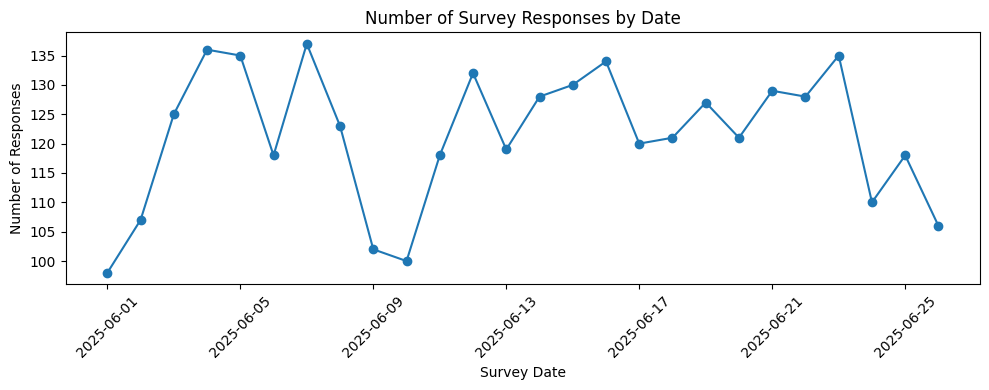

In [97]:
date_counts = df_clean["Survey_Date"].value_counts().sort_index()
plt.figure(figsize=(10,4))
plt.plot(date_counts.index, date_counts.values, marker="o")
plt.title("Number of Survey Responses by Date")
plt.xlabel("Survey Date")
plt.ylabel("Number of Responses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The number of responses changes from day to day. This shows that participation was not equal on every survey date. The data therefore represent a short survey period rather than a full year.

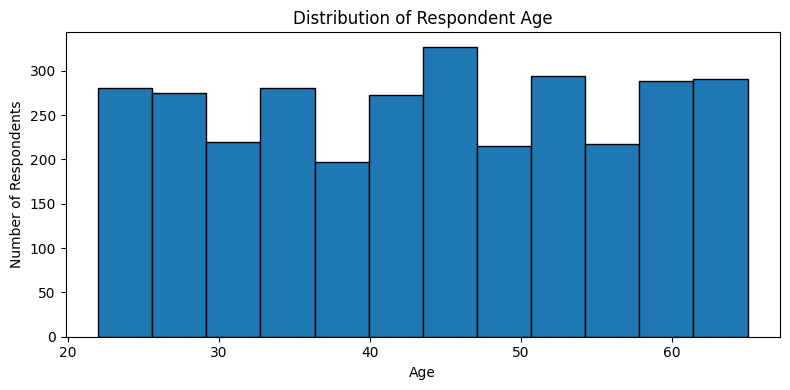

In [98]:
plt.figure(figsize=(8,4))
plt.hist(df_clean["Age"], bins=12, edgecolor="black")
plt.title("Distribution of Respondent Age")
plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

Respondent ages range from 22 to 65 years. The ages are spread across the adult working population, with many respondents around the middle of the age range.

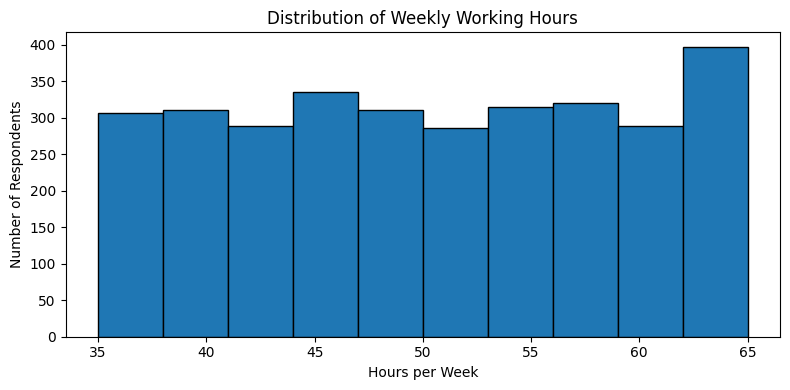

In [99]:
plt.figure(figsize=(8,4))
plt.hist(df_clean["Hours_Per_Week"], bins=10, edgecolor="black")
plt.title("Distribution of Weekly Working Hours")
plt.xlabel("Hours per Week")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

Working hours range from 35 to 65 hours per week. The centre is around 50 hours, which agrees with the mean and median values.

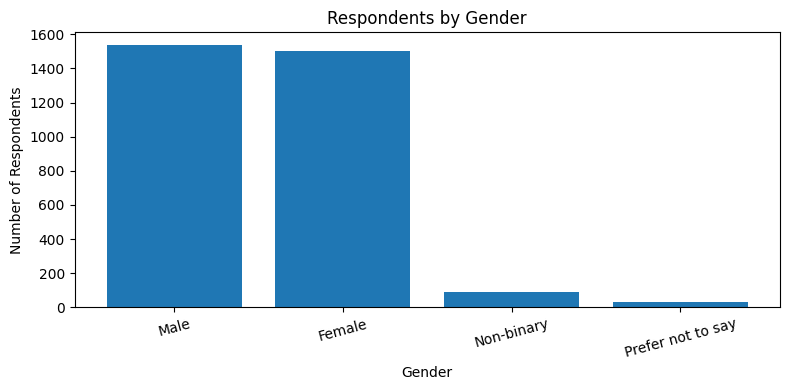

In [100]:
c = df_clean["Gender"].value_counts()
plt.figure(figsize=(8,4))
plt.bar(c.index, c.values)
plt.title("Respondents by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Male and female respondents are the two largest groups. The dataset also includes non-binary and prefer-not-to-say responses, so the data contain more than two gender categories.

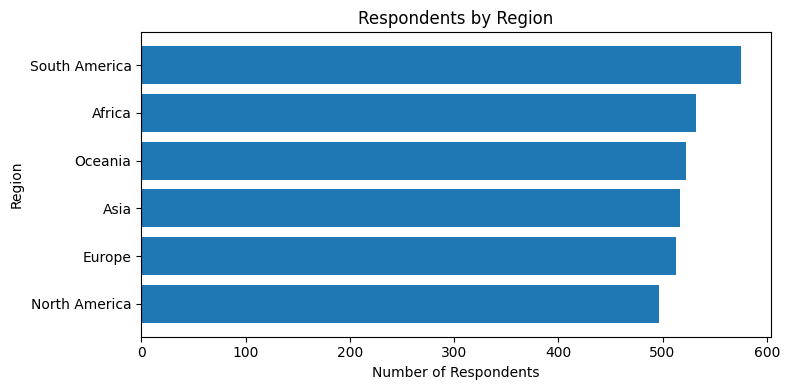

In [101]:
c = df_clean["Region"].value_counts().sort_values()
plt.figure(figsize=(8,4))
plt.barh(c.index, c.values)
plt.title("Respondents by Region")
plt.xlabel("Number of Respondents")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

All six regions are represented. South America has the largest number of respondents, while North America has the smallest. The regional sample sizes are therefore not equal.

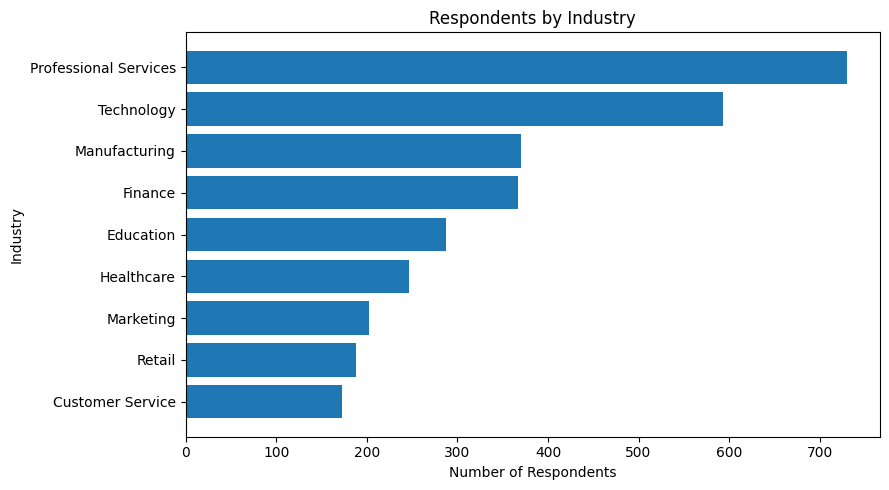

In [102]:
c = df_clean["Industry"].value_counts().sort_values()
plt.figure(figsize=(9,5))
plt.barh(c.index, c.values)
plt.title("Respondents by Industry")
plt.xlabel("Number of Respondents")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

The respondents come from several industries. Some industries have more respondents than others, so percentage comparisons are more useful than raw counts when comparing groups.

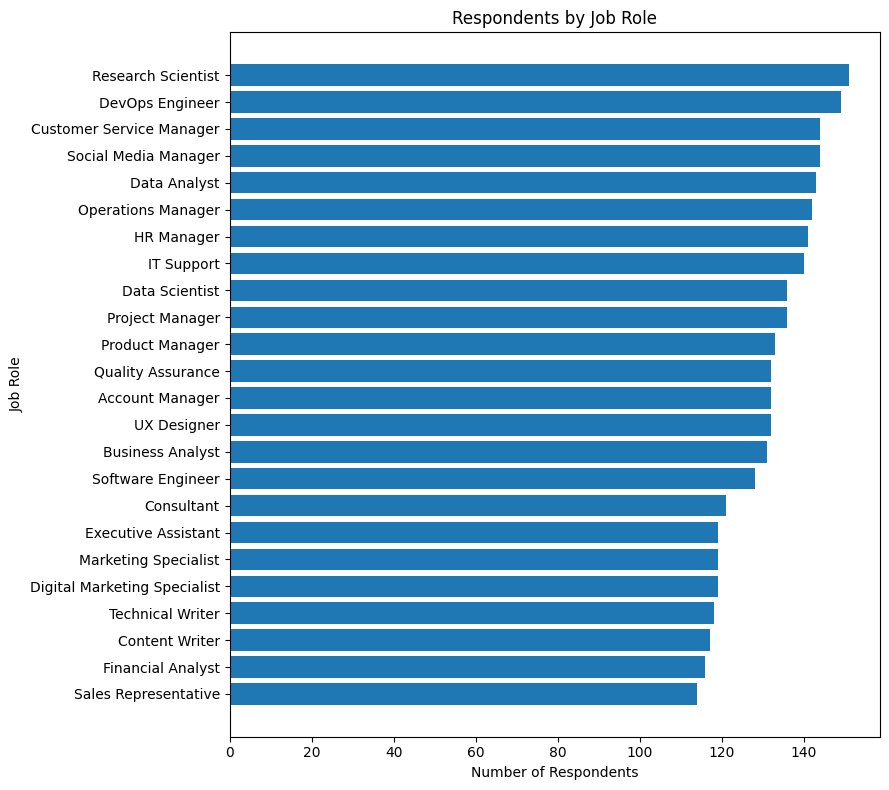

In [103]:
c = df_clean["Job_Role"].value_counts().sort_values()
plt.figure(figsize=(9,8))
plt.barh(c.index, c.values)
plt.title("Respondents by Job Role")
plt.xlabel("Number of Respondents")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()

here are many different job roles. This gives the dataset useful occupational variety, although the number of respondents is not the same for every role.

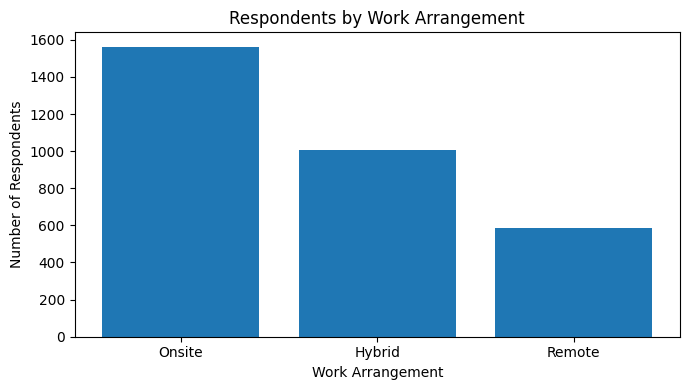

In [104]:
c = df_clean["Work_Arrangement"].value_counts()
plt.figure(figsize=(7,4))
plt.bar(c.index, c.values)
plt.title("Respondents by Work Arrangement")
plt.xlabel("Work Arrangement")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

Onsite is the largest work-arrangement group, followed by hybrid and then remote. This difference in group size must be remembered when comparing work arrangements.

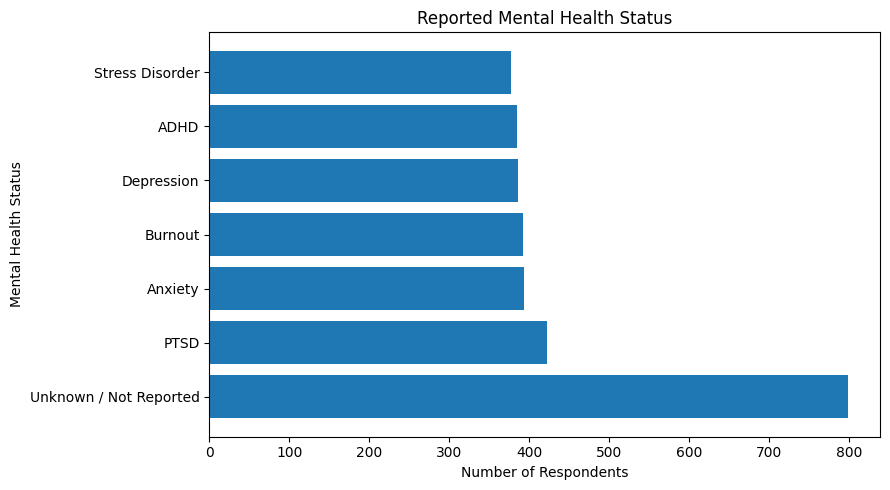

In [105]:
c = df_clean["Mental_Health_Status"].value_counts()
plt.figure(figsize=(9,5))
plt.barh(c.index, c.values)
plt.title("Reported Mental Health Status")
plt.xlabel("Number of Respondents")
plt.ylabel("Mental Health Status")
plt.tight_layout()
plt.show()

There is a large `Unknown / Not Reported` group because the original data had many missing mental-health responses. This means the reported categories should not be treated as a complete measure of mental-health prevalence.

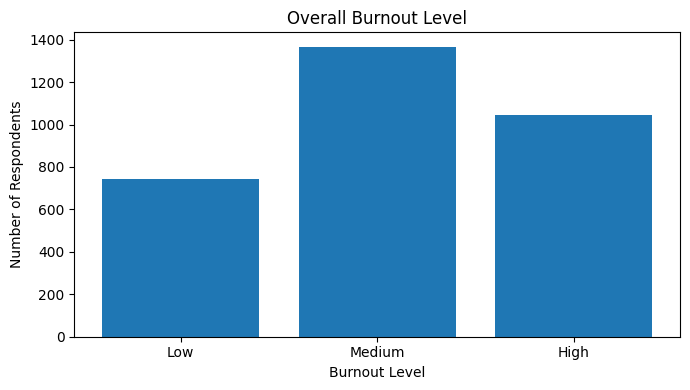

In [106]:
c = df_clean["Burnout_Level"].value_counts().reindex(["Low","Medium","High"])
plt.figure(figsize=(7,4))
plt.bar(c.index, c.values)
plt.title("Overall Burnout Level")
plt.xlabel("Burnout Level")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

Medium burnout is the most common level. High burnout is also common, while low burnout is the smallest group. This makes burnout an important variable for the relationship analysis.

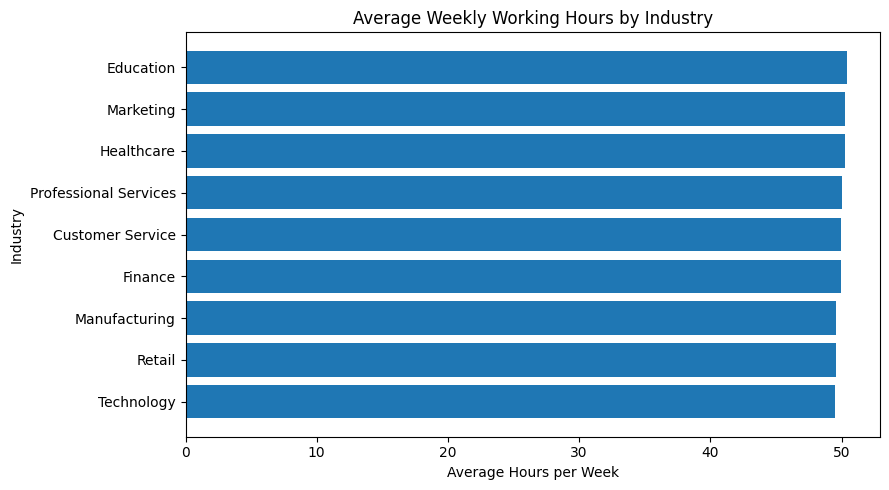

,Average_Hours
Industry,
Technology,49.47
Retail,49.59
Manufacturing,49.59
Finance,49.95
Customer Service,49.96
Professional Services,50.06
Healthcare,50.23
Marketing,50.24
Education,50.41


In [107]:
industry_hours = df_clean.groupby("Industry")["Hours_Per_Week"].mean().sort_values()
plt.figure(figsize=(9,5))
plt.barh(industry_hours.index, industry_hours.values)
plt.title("Average Weekly Working Hours by Industry")
plt.xlabel("Average Hours per Week")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()
display(industry_hours.round(2).to_frame("Average_Hours"))

The average number of working hours is fairly similar across industries. Education is around 50.4 hours per week, while Technology is around 49.5 hours. The difference is small.

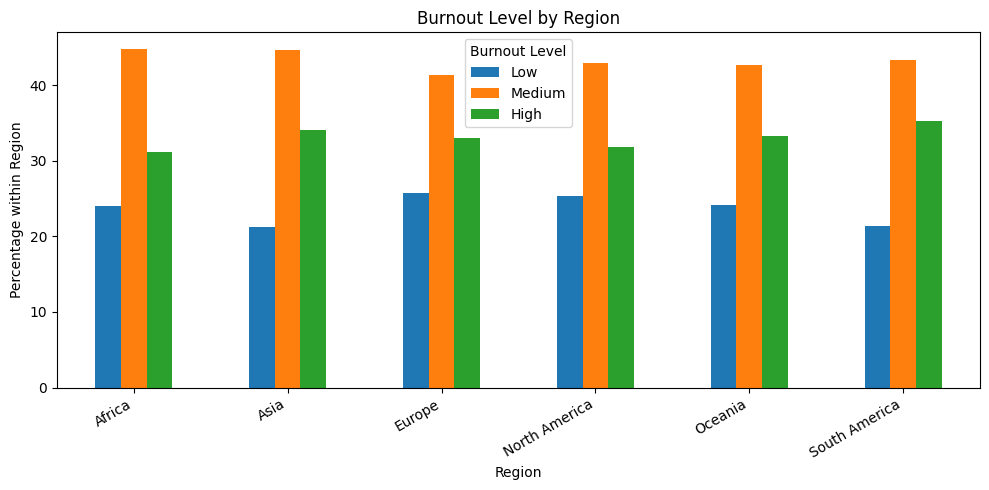

In [108]:
region_burnout = pd.crosstab(
    df_clean["Region"], df_clean["Burnout_Level"], normalize="index"
).reindex(columns=["Low","Medium","High"]) * 100
ax = region_burnout.plot(kind="bar", figsize=(10,5))
ax.set_title("Burnout Level by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Percentage within Region")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Burnout Level")
plt.tight_layout()
plt.show()

The burnout percentages are not exactly the same in every region. Percentages are used instead of raw counts because the regions contain different numbers of respondents.

# 5. Relationships between variables

I selected relationships that make sense for the variables in this dataset.

The main relationships are:

1. Work arrangement and burnout
2. Work arrangement and mental-health status
3. Age group and burnout
4. Working hours and burnout
5. Age and working hours
6. Region and working hours

These are associations. But they do not prove cause and effect.

 ## 1. Work arrangement and burnout

In [109]:
counts = pd.crosstab(df_clean["Work_Arrangement"], df_clean["Burnout_Level"])
percent = pd.crosstab(
    df_clean["Work_Arrangement"], df_clean["Burnout_Level"], normalize="index"
) * 100

## Counts

In [110]:
display(counts)

Burnout_Level,High,Low,Medium
Work_Arrangement,,,
Hybrid,360,193,454
Onsite,413,471,678
Remote,273,81,234


# Percentages within each work arrangement

In [111]:
display(percent.round(1))

Burnout_Level,High,Low,Medium
Work_Arrangement,,,
Hybrid,35.7,19.2,45.1
Onsite,26.4,30.2,43.4
Remote,46.4,13.8,39.8


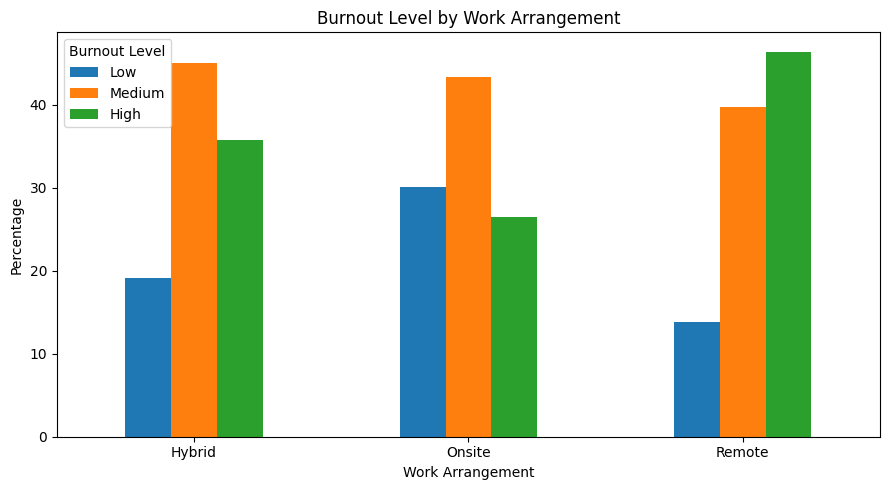

In [112]:
ax = percent.reindex(columns=["Low","Medium","High"]).plot(
    kind="bar", figsize=(9,5)
)
ax.set_title("Burnout Level by Work Arrangement")
ax.set_xlabel("Work Arrangement")
ax.set_ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Burnout Level")
plt.tight_layout()
plt.show()

### Interpretation: Work arrangement and burnout

This is the clearest relationship in the analysis.

High burnout is approximately:

Remote workers therefore have the highest proportion of high burnout in this sample.
Onsite workers have the highest proportion of low burnout.

However, this does not prove that remote work causes burnout. Other factors may explain some of the difference.

# 2. Work arrangement and mental-health status

In [113]:
mental = pd.crosstab(
    df_clean["Work_Arrangement"], df_clean["Mental_Health_Status"],
    normalize="index"
) * 100
display(mental.round(1))

Mental_Health_Status,ADHD,Anxiety,Burnout,Depression,PTSD,Stress Disorder,Unknown / Not Reported
Work_Arrangement,,,,,,,
Hybrid,12.7,12.1,12.1,12.0,12.8,11.6,26.6
Onsite,11.9,12.6,13.3,12.7,13.8,12.2,23.6
Remote,12.1,12.8,10.7,11.4,13.3,12.1,27.7


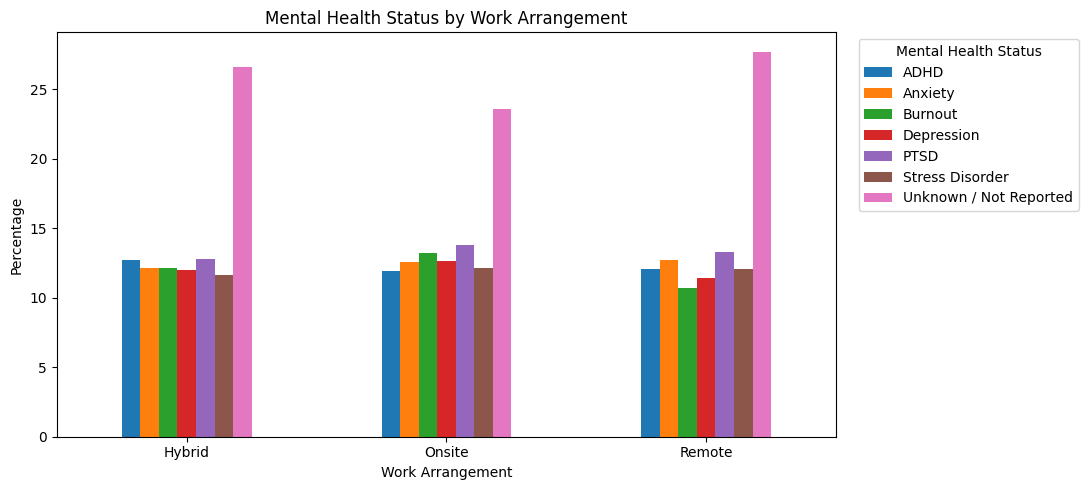

In [114]:
ax = mental.plot(kind="bar", figsize=(11,5))
ax.set_title("Mental Health Status by Work Arrangement")
ax.set_xlabel("Work Arrangement")
ax.set_ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Mental Health Status", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout()
plt.show()

### Interpretation: Work arrangement and mental health

Mental-health categories occur in all three work arrangements. There are differences between the groups, but the pattern is not as clear as the burnout relationship.

The large `Unknown / Not Reported` group also limits how confidently we can compare mental-health categories.

## 3. Age group and burnout

In [115]:
age_burn = pd.crosstab(
    df_clean["Age_Group"], df_clean["Burnout_Level"], normalize="index"
) * 100
display(age_burn.round(1))

Burnout_Level,High,Low,Medium
Age_Group,,,
18-29,32.1,25.8,42.2
30-39,36.7,21.4,41.9
40-49,31.1,24.4,44.5
50-59,31.5,24.6,43.9
60+,34.9,21.4,43.7


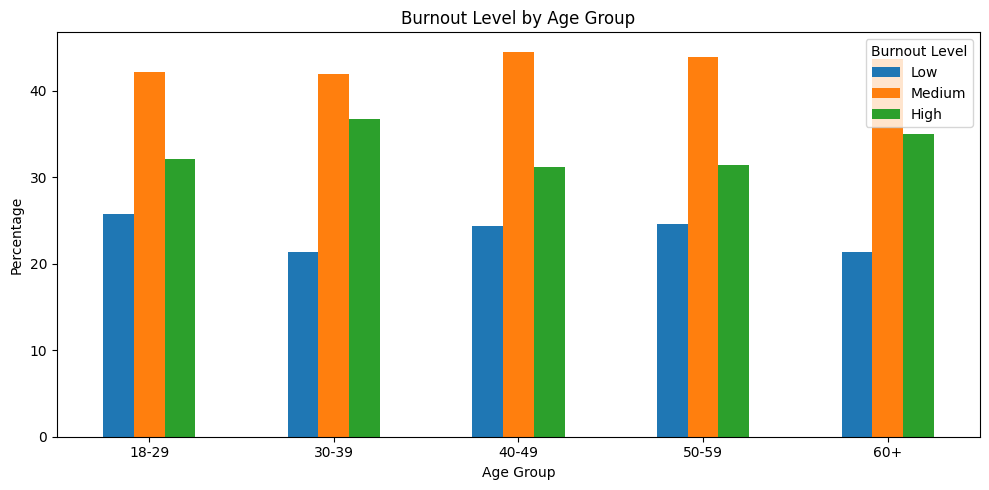

In [116]:
ax = age_burn.reindex(columns=["Low","Medium","High"]).plot(
    kind="bar", figsize=(10,5)
)
ax.set_title("Burnout Level by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Burnout Level")
plt.tight_layout()
plt.show()

### Interpretation: Age group and burnout

Burnout is different across age groups, but there is no simple rule saying that burnout always increases or always decreases with age.

The 30–39 group has a relatively high share of high burnout. Other age groups also have noticeable high-burnout levels. This suggests that age may be related to burnout in a more complicated way.

# 4. Working hours and burnout

In [117]:
hour_burn = pd.crosstab(
    df_clean["Hours_Group"], df_clean["Burnout_Level"], normalize="index"
) * 100
display(hour_burn.round(1))

Burnout_Level,High,Low,Medium
Hours_Group,,,
≤39,34.0,22.3,43.7
40-49,33.0,23.4,43.5
50-59,32.7,24.7,42.7
60+,33.4,23.1,43.5


Average hours by burnout level

In [118]:
display(df_clean.groupby("Burnout_Level")["Hours_Per_Week"]
        .agg(["count","mean","median","min","max"])
        .reindex(["Low","Medium","High"]).round(2))

,count,mean,median,min,max
Burnout_Level,,,,,
Low,745,50.09,50.0,35,65
Medium,1366,49.88,50.0,35,65
High,1046,49.81,50.0,35,65


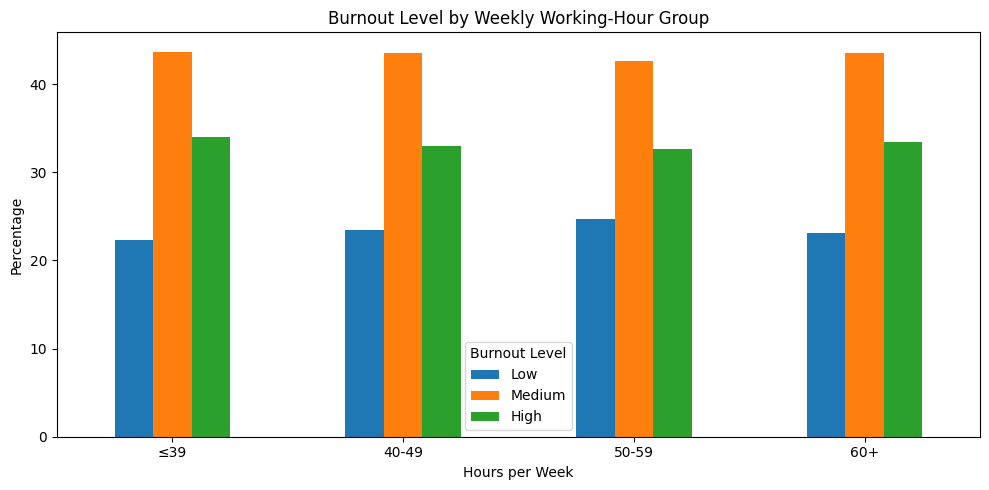

In [119]:
ax = hour_burn.reindex(columns=["Low","Medium","High"]).plot(
    kind="bar", figsize=(10,5)
)
ax.set_title("Burnout Level by Weekly Working-Hour Group")
ax.set_xlabel("Hours per Week")
ax.set_ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Burnout Level")
plt.tight_layout()
plt.show()

### Interpretation: Working hours and burnout

therefore, working hours are average. though working hours alone do not show a strong difference between burnout groups in this dataset. This is useful because it shows why we should inspect the actual data rather than assume that longer hours automatically mean higher burnout.

# 5. Age and working hours

In [120]:
correlation = df_clean[["Age","Hours_Per_Week"]].corr().loc["Age","Hours_Per_Week"]
print("Pearson correlation:", round(correlation, 4))

Pearson correlation: 0.0037


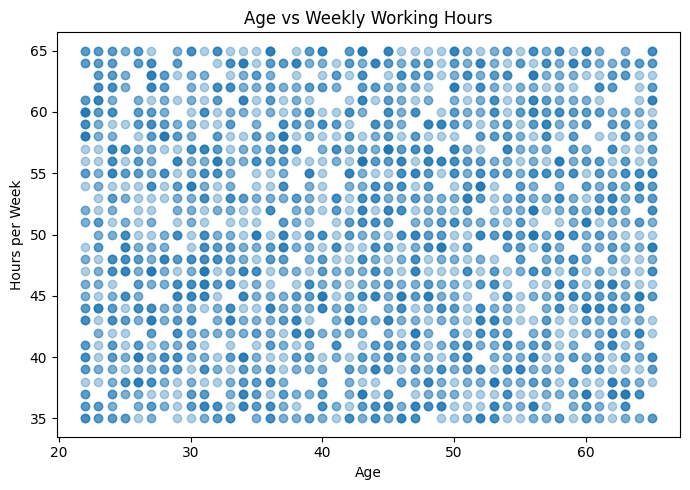

In [121]:
plt.figure(figsize=(7,5))
plt.scatter(df_clean["Age"], df_clean["Hours_Per_Week"], alpha=0.35)
plt.title("Age vs Weekly Working Hours")
plt.xlabel("Age")
plt.ylabel("Hours per Week")
plt.tight_layout()
plt.show()

### Interpretation: Age and working hours

The Pearson correlation is **{corr:.4f}**, which is almost zero.

This means there is almost no linear relationship between age and weekly working hours in this sample. The scatter plot also does not show a clear upward or downward pattern.

# 6. Region and working hours

In [122]:
region_hours = df_clean.groupby("Region")["Hours_Per_Week"].mean().sort_values(ascending=False)

display(region_hours.round(2).to_frame("Average_Hours"))

,Average_Hours
Region,
Africa,50.23
Oceania,50.17
South America,50.00
North America,49.75
Europe,49.63
Asia,49.61


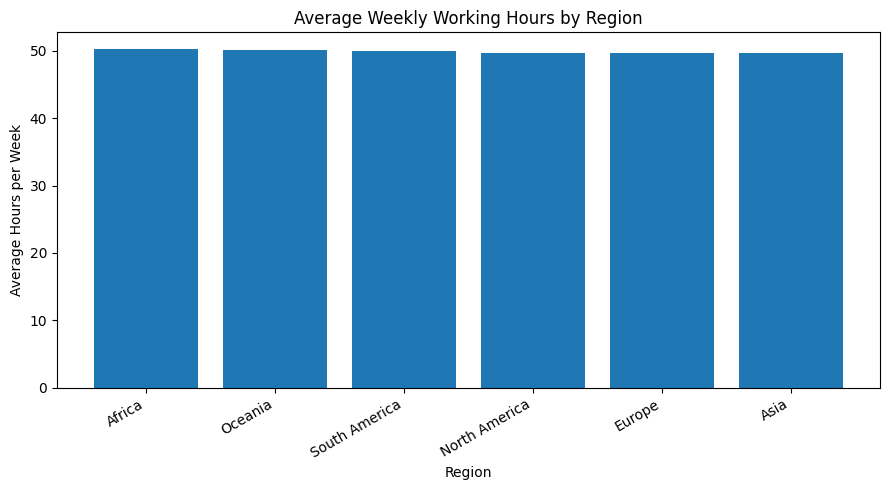

In [123]:
plt.figure(figsize=(9,5))
plt.bar(region_hours.index, region_hours.values)
plt.title("Average Weekly Working Hours by Region")
plt.xlabel("Region")
plt.ylabel("Average Hours per Week")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Interpretation: Region and working hours

The regional averages are quite close. Africa is around 50.2 hours per week, while Asia is around 49.6 hours.

The difference is small, so region does not appear to make a large difference to average working hours in this dataset.

# Overall findings

After looking carefully at the data, several findings stand out.

### Finding 1: The dataset is large and varied
There are 3,157 respondents from different regions, industries, job roles, genders and work arrangements.

### Finding 2: Missing mental-health information was the main cleaning problem
There were 799 missing mental-health responses. I kept these respondents and labelled the missing values `Unknown / Not Reported`.

### Finding 3: Burnout is common
Medium burnout is the largest burnout group, and high burnout is also a large group.

### Finding 4: Work arrangement and burnout have a noticeable relationship
Remote workers have the highest percentage of high burnout in the sample.

### Finding 5: Working hours and burnout are not strongly separated
The average hours are very similar for low-, medium- and high-burnout groups.

### Finding 6: Age and working hours are almost unrelated
The correlation is very close to zero.

### Finding 7: Region and industry do not create large differences in average working hours
The averages are fairly close across these groups.

# 7. Limitations

here are a few things that I must be careful about.

1. This is survey data. Respondents provide their own answers, so self-reported information may not always be perfect.

2. The data were collected during a limited period in June 2025. The findings should not automatically be treated as a description of every employee everywhere.

3. The analysis shows relationships, not causes. For example, the higher high-burnout percentage among remote workers does not prove that remote work causes burnout.

4. The large missing mental-health group means that mental-health results should be interpreted carefully.


# 8. Conclusion

This analysis followed the main steps required in the assignment.

I started by understanding the dataset and describing every variable. I then inspected the raw data and found the main problems. The most important problem was missing mental-health information. Instead of deleting many respondents or guessing their answers, I clearly labelled those responses as `Unknown / Not Reported`.

I then used summary statistics and graphs to understand the data. Finally, I investigated meaningful relationships between work arrangement, burnout, mental health, age, working hours and region.

The strongest result was the relationship between **work arrangement and burnout**. Remote workers had the highest proportion of high burnout in this sample. However, I cannot say that remote work caused the burnout because the data do not prove cause and effect.

Another useful finding was that **working hours were very similar across burnout groups**, and **age had almost no linear relationship with weekly working hours.